In [1]:
import pandas as pd
import sys
from pathlib import Path 
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import numpy as np
import geopandas as gpd
import os
import joblib

sys.path.insert(0, str(Path("../src").resolve()))
from idx_exchange_data_science.preprocessing import initial_cleaning, clean_living_area, select_training_window,\
    filter_close_price, clean_lot_size, clean_coordinates, CoordinateImputer, add_property_age_at_sale, add_bed_bath_ratio,\
    clean_property_characteristics, clean_postal_code, add_binary_missing_indicators, clean_categorical_features,\
    add_school_district_features,  add_hoa_features, add_comparable_sales, add_flooring_features
    
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV

## Advanced Models: XGBoost and LightGBM

This notebook develops and evaluates XGBoost and LightGBM models to predict residential property closing prices (ClosePrice) using historical California real estate data. The models are evaluated against previously developed baseline models, including Linear Regression, Decision Tree, and Random Forest. Light hyperparameter tuning is performed to optimize model performance.

### Data Loading and Preprocessing

The dataset consists of monthly CSV files from the California Regional Multiple Listing Service (CRMLS), covering January 2024 through April 2026.

The data is split chronologically into training, validation (March 2026), and test (April 2026) sets. Reusable cleaning functions from the idx_exchange.preprocessing_data_science module are applied to prepare the datasets for modeling.

Preprocessing parameters are learned from the training data, with fold-specific fitting used during cross-validation to prevent data leakage.

In [2]:
# Create a Path object to the folder containing the monthly CSV files
data_path = Path("../data")

# Get all the CSV files from the data folder and sort them chronologically by filename
csv_files = sorted(data_path.glob("*.csv"))

In [3]:
# Split the monthly CSV files into training, validation, and test sets
train_files = csv_files[:-2]
validation_file = csv_files[-2]
test_file = csv_files[-1]

In [4]:
# Read each monthly training file into a DataFrame
train_dfs = []

for file in train_files:
    monthly_data = pd.read_csv(file)

    # Extract the year and month from the CSV filename
    source_month = file.stem.replace("CRMLSSold", "").replace("_filled", "")
    monthly_data["SourceMonth"] = source_month[:4] + "-" + source_month[4:6]
    
    train_dfs.append(monthly_data)
    
# Combine the monthly training DataFrames into a single DataFrame
initial_data = pd.concat(train_dfs, ignore_index=True)

/var/folders/s8/2hb9crtx0f59zm5tv6jsyvhm0000gn/T/ipykernel_8038/84281947.py:5: DtypeWarning: Columns (2,36,39,56,74) have mixed types. Specify dtype option on import or set low_memory=False.
  monthly_data = pd.read_csv(file)
/var/folders/s8/2hb9crtx0f59zm5tv6jsyvhm0000gn/T/ipykernel_8038/84281947.py:5: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  monthly_data = pd.read_csv(file)
/var/folders/s8/2hb9crtx0f59zm5tv6jsyvhm0000gn/T/ipykernel_8038/84281947.py:5: DtypeWarning: Columns (4,74) have mixed types. Specify dtype option on import or set low_memory=False.
  monthly_data = pd.read_csv(file)


In [5]:
# Load validation and test files
validation_df = pd.read_csv(validation_file)
test_df = pd.read_csv(test_file)

# Add source month to each dataset
for df, file in [(validation_df, validation_file), (test_df, test_file)]:
    source_month = file.stem.replace("CRMLSSold", "").replace("_filled", "")
    df["SourceMonth"] = source_month[:4] + "-" + source_month[4:6]

### Initial Data Cleaning

Apply the initial cleaning rules to remove invalid records, including non-California properties, duplicate transactions, non-single-family residences, inconsistent dates, and invalid closing prices. The same cleaning rules are applied to all three datasets.

In [6]:
# Apply the initial cleaning rules to all datasets
clean_train_df, train_log = initial_cleaning(initial_data)
clean_validation_df, validation_log = initial_cleaning(validation_df)
clean_test_df, test_log = initial_cleaning(test_df)

In [7]:
display(train_log)

,step,Before,Removed,Removed (%),Remaining
0,California filtering,568074,76,0.0134,567998
1,Duplicate removal,567998,2911,0.5125,565087
2,Property-type filtering,565087,280370,49.6154,284717
3,Date consistency,284717,39,0.0137,284678
4,Target cleaning,284678,3,0.0011,284675


### Feature Selection

Select the relevant property features, target variable (ClosePrice), and tracking columns required for preprocessing and modeling. 

Features with 80% or more missing values are excluded from modeling. Based on the full 26 months training dataset, `BasementYN`, `BuildingAreaTotal`, and school-related columns exceed this threshold. 

Note: Detailed geographic layer using school districts will be added in Week 6 (Feature engineering). 

In [8]:
feature_columns = ["AttachedGarageYN", "BathroomsTotalInteger", "BedroomsTotal", "Flooring",
                   "City", "CountyOrParish", "FireplaceYN", "GarageSpaces", "Latitude",
                   "Longitude", "LivingArea","LotSizeSquareFeet", "LotSizeAcres", "NewConstructionYN",
                   "ParkingTotal", "PoolPrivateYN", "PostalCode", "ViewYN", "YearBuilt", "AssociationFee", "AssociationFeeFrequency"]

target_column = ["ClosePrice"]
tracking_columns = ["SourceMonth", "CloseDate", "ListingContractDate"]

key_columns = feature_columns + target_column + tracking_columns

In [9]:
clean_train_df = clean_train_df[key_columns].copy()
clean_validation_df = clean_validation_df[key_columns].copy()
clean_test_df = clean_test_df[key_columns].copy()

In [10]:
# Perserve the datasets before further preprocessing
base_train_df = clean_train_df.copy()
base_validation_df = clean_validation_df.copy()
base_test_df = clean_test_df.copy()

### Training Window Selection and Target Filtering

Select an adjustable training window of X months preceding March 2026. Calculate the 0.5th and 99.5th percentile ClosePrice thresholds from the selected training data and apply the same thresholds to the datasets according to the agreed cleaning rules.

In [11]:
X = 18  # Try 6, 12, 18

# Selcet training window 
clean_train_df = select_training_window(base_train_df, n_months=X, validation_month="2026-03")

print(f"Training window: {X} months")
print(f"Training records: {len(clean_train_df)}")

Training window: 18 months
Training records: 190549


In [12]:
# Calculate thresholds from the selected X-month training window
lower_threshold = clean_train_df["ClosePrice"].quantile(0.005)
upper_threshold = clean_train_df["ClosePrice"].quantile(0.995)

# Remove records outside the training-derived ClosePrice thresholds
clean_train_df, train_price_log = filter_close_price(clean_train_df, lower_threshold, upper_threshold)
clean_validation_df, validation_price_log = filter_close_price(clean_validation_df, lower_threshold, upper_threshold)
clean_test_df, test_price_log = filter_close_price(clean_test_df, lower_threshold, upper_threshold)

In [13]:
# # Apply log transformation to ClosePrice for all datasets
for df in[clean_train_df, clean_validation_df, clean_test_df]:
    df["LogClosePrice"] = np.log1p(df["ClosePrice"])

### Numerical Feature Cleaning

#### LivingArea and LotSizeSquareFeet

Clean numerical property features by removing records with nonpositive LivingArea values while retaining missing values for later imputation. Standardize lot-size measurements by converting valid acreage values to square feet when LotSizeSquareFeet is missing.

In [14]:
# Remove nonpositive LivingArea values while retaining missing values
clean_train_df, train_area_log = clean_living_area(clean_train_df)
clean_validation_df, validation_log = clean_living_area(clean_validation_df)
clean_test_df, test_log = clean_living_area(clean_test_df)

In [15]:
# Clean lot sizes and recover missing square footage using acres
clean_train_df, train_recovered_rows = clean_lot_size(clean_train_df)
clean_validation_df, validation_recovered_rows = clean_lot_size(clean_validation_df)
clean_test_df, test_recovered_rows = clean_lot_size(clean_test_df)

In [16]:
# Summarize the number of recovered lot-size values in each dataset
display(pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Lot sizes recovered": [train_recovered_rows, validation_recovered_rows, test_recovered_rows]}))

,Dataset,Lot sizes recovered
0,Training,15
1,Validation,2
2,Test,0


#### Property Characteristics 

Property characteristics, including bedrooms, bathrooms, garage spaces, and parking counts, are evaluated using provisional plausibility ranges. Invalid values are marked as missing for later imputation rather than removing the corresponding records.

These cleaning rules have not yet been finalized and may be revised following team discussion and further review.

In [17]:
# Clean property characteristics and record invalid values
clean_train_df, train_property_log = clean_property_characteristics(clean_train_df)
clean_validation_df, validation_property_log = clean_property_characteristics(clean_validation_df)
clean_test_df, test_property_log = clean_property_characteristics(clean_test_df)

In [18]:
# Summarize invalid property characteristic values
property_logs = pd.DataFrame({ "Training": train_property_log,
                               "Validation": validation_property_log,
                               "Test": test_property_log})

display(property_logs)

,Training,Validation,Test
BedroomsTotal,61,6,2
BathroomsTotalInteger,44,5,3
GarageSpaces,343,19,21
ParkingTotal,707,45,38


### Geographic Feature Cleaning

Standardize postal codes to five-digit ZIP codes and mark latitude and longitude values outside California's geographic bounds as missing. Missing coordinates will be imputed later using training-derived ZIP-level, county-level, and overall medians within the modeling pipeline.

In [19]:
# Standardize postal codes for all datasets
clean_train_df = clean_postal_code(clean_train_df)
clean_validation_df = clean_postal_code(clean_validation_df)
clean_test_df = clean_postal_code(clean_test_df)

In [20]:
# Mark invalid coordinates as missing
clean_train_df = clean_coordinates(clean_train_df)
clean_validation_df = clean_coordinates(clean_validation_df)
clean_test_df = clean_coordinates(clean_test_df)

### Feature Engineering

Calculate property age and create missingness indicators for binary property features. Missing values are retained for imputation within the modeling pipeline.

In [21]:
# Calculate property age at sale for all datasets
clean_train_df = add_property_age_at_sale(clean_train_df)
clean_validation_df = add_property_age_at_sale(clean_validation_df)
clean_test_df = add_property_age_at_sale(clean_test_df)

In [22]:
# Apply missingness indicator for binary features to all datasets
clean_train_df = add_binary_missing_indicators(clean_train_df)
clean_validation_df = add_binary_missing_indicators(clean_validation_df)
clean_test_df = add_binary_missing_indicators(clean_test_df)

### Categorical Feature Cleaning

Standardize `City`, `CountyOrParish`, and `PostalCode` by converting values to strings, removing surrounding whitespace, and replacing missing values with `"Unknown"`.

Target encoding will be performed within the modeling pipeline. The encoding approach is provisional and subject to further team review.

In [23]:
# Standardize categorical features for target encoding
clean_train_df = clean_categorical_features(clean_train_df)
clean_validation_df = clean_categorical_features(clean_validation_df)
clean_test_df = clean_categorical_features(clean_test_df)

## Preprocessing Pipeline

Define preprocessing steps for numerical, binary, and categorical features using sklearn pipelines. Missing values are imputed using training-derived statistics, numerical features are standardized, and categorical features are target-encoded.

Learned preprocessing parameters within the modeling pipeline are fitted separately for each cross-validation training fold to reduce data leakage. Fixed data-cleaning rules and training-derived ClosePrice thresholds are applied before cross-validation

In [24]:
# define the columns used by each pipeline.
area_columns = ["LivingArea", "LotSizeSquareFeet"]
property_columns = ["BedroomsTotal", "BathroomsTotalInteger", "GarageSpaces", "ParkingTotal"]
coordinate_columns = ["Latitude", "Longitude"]
age_columns = ["PropertyAgeAtSale"]
binary_columns = ["AttachedGarageYN", "FireplaceYN", "NewConstructionYN", "PoolPrivateYN", "ViewYN"]
binary_missing_columns = [f"{col}_Missing" for col in binary_columns]
categorical_columns = ["City", "CountyOrParish","PostalCode"]

In [25]:
# Impute, log-transform, and standardize area features
area_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(np.log1p)),
                          ("scaling", StandardScaler())])

# Impute property counts using mode, then standardize
property_pipeline = Pipeline([("imputation", SimpleImputer(strategy="most_frequent")),
                              ("scaling", StandardScaler())])

# Impute and standardize property age
property_age_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")),
                                  ("scaling", StandardScaler())])

# Standardize coordinates after geographic imputation
coordinate_pipeline = Pipeline([("scaling", StandardScaler())])

# Impute binary features using mode
binary_pipeline = Pipeline([("imputation", SimpleImputer(strategy="most_frequent"))])

# Encode high-cardinality categorical features
categorical_pipeline = Pipeline([("target_encoding", TargetEncoder(target_type="continuous", cv=5,\
                                                                   shuffle=True, random_state=42))])

In [26]:
# Build the ColumnTransformer by assigning each pipeline to its corresponding features.
preprocessor = ColumnTransformer([("area", area_pipeline, area_columns),
                                  ("property", property_pipeline, property_columns),
                                  ("coordinates", coordinate_pipeline, coordinate_columns),
                                  ("property_age", property_age_pipeline, age_columns),
                                  ("binary", binary_pipeline, binary_columns),
                                  ("binary_missing", "passthrough", binary_missing_columns),
                                  ("categorical", categorical_pipeline, categorical_columns)])

In [27]:
# Prepare features and target 
model_features = (area_columns + property_columns + coordinate_columns +\
                  age_columns + binary_columns + binary_missing_columns + categorical_columns)

X_train = clean_train_df[model_features].copy()
y_train = clean_train_df["LogClosePrice"]

X_val = clean_validation_df[model_features].copy()
y_val = clean_validation_df["LogClosePrice"]

X_test = clean_test_df[model_features].copy()
y_test = clean_test_df["LogClosePrice"]

In [28]:
# Calculate Mean Absolute Percentage Error
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Calculate Median Absolute Percentage Error
def mdape(y_true, y_pred):
    return np.median(np.abs((y_true - y_pred) / y_true)) * 100

In [29]:
# Custom scorer (calculate R² on the original ClosePrice scale)
def close_price_r2(estimator, X, y):
    predictions_log = estimator.predict(X)

    actual_prices = np.expm1(y)
    predicted_prices = np.expm1(predictions_log)

    return r2_score(actual_prices, predicted_prices)

def dollar_mape(estimator, X, y):
    return mape(np.expm1(y), np.expm1(estimator.predict(X)))

def dollar_mdape(estimator, X, y):
    return mdape(np.expm1(y), np.expm1(estimator.predict(X)))

## Additional Feature Engineering

This section introduces additional features to capture property characteristics and geographicinformation that may improve home sale price predictions. Model performance will be compared against the original baseline models.

### Bedroom to Bathroom Ratio
Create a `BedBathRatio` feature to capture the relationship between the number of bedrooms and bathrooms in a property.

In [30]:
# Create copies to preserve the original datasets
train_fe = clean_train_df.copy()
validation_fe = clean_validation_df.copy()
test_fe = clean_test_df.copy()

# Add bedroom to bathroom ratio
train_ratio = add_bed_bath_ratio(clean_train_df)
validation_ratio = add_bed_bath_ratio(clean_validation_df)
test_ratio = add_bed_bath_ratio(clean_test_df)

### School District Features

Add school district features using the California School District Areas 2024–25 GeoJSON dataset. Property coordinates are spatially joined with school district boundaries to identify the corresponding elementary and high school districts. Unified districts are assigned to both categories.

In [31]:
# Load California school district boundaries
districts_df = gpd.read_file("../external_data/GeoJSON.geojson")

# Convert property coords into geographic points
train_geo = gpd.GeoDataFrame(train_fe.copy(), geometry=gpd.points_from_xy(
    train_fe["Longitude"], train_fe["Latitude"]), crs="EPSG:4326")

validation_geo = gpd.GeoDataFrame(validation_fe.copy(),
    geometry=gpd.points_from_xy(validation_fe["Longitude"], validation_fe["Latitude"]), crs="EPSG:4326")

test_geo = gpd.GeoDataFrame(test_fe.copy(),
    geometry=gpd.points_from_xy(test_fe["Longitude"], test_fe["Latitude"]), crs="EPSG:4326")

In [32]:
# Elementary school districts (including unified districts)
elementary_districts = districts_df[districts_df["DistrictType"].
     isin(["Elementary", "Unified"])][["DistrictName", "DistrictType", "geometry", "SEDpct"]].copy()

# High school districts (including unified districts)
high_school_districts = districts_df[districts_df["DistrictType"].
    isin(["High", "Unified"])][["DistrictName", "DistrictType", "geometry"]].copy()

# Rename columns to match our new features
elementary_districts = elementary_districts.rename(
    columns={"DistrictName": "ElementarySchoolDistrict"})

high_school_districts = high_school_districts.rename(
    columns={"DistrictName": "HighSchoolDistrict"})

In [33]:
# Add school district features to training data
train_school = add_school_district_features(clean_train_df, elementary_districts, high_school_districts)

# Add school district features to validation data
validation_school = add_school_district_features(clean_validation_df, elementary_districts, high_school_districts)

# Add school district features to test data
test_school = add_school_district_features(clean_test_df, elementary_districts, high_school_districts)

In [34]:
# Combine bedroom to bathroom ratio and school district features
train_fe = add_school_district_features(train_ratio, elementary_districts, high_school_districts)

validation_fe = add_school_district_features(validation_ratio, elementary_districts, high_school_districts)

test_fe = add_school_district_features(test_ratio, elementary_districts, high_school_districts)

### School District Feature Engineering Summary

School district features were assigned to the training, validation, and test datasets using spatial joins. Elementary and high school districts were identified separately, with unified districts included in both categories.

The spatial joins preserved the original number of property records across all three datasets. In the training set, 138 properties had missing elementary school district assignments, while 260 had missing high school district assignments. Missing school district values were retained and handled as a separate category by TargetEncoder.

In [35]:
# Impute missing bedroom to bathroom ratios using median and then standardize
ratio_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")),
                           ("scaling", StandardScaler())])
ratio_column = ["BedBathRatio"]
school_district_columns = ["ElementarySchoolDistrict", "HighSchoolDistrict"]
sed_columns = ["DistrictSEDPct"]

# Target encoding for school district features
school_district_pipeline = Pipeline([("target_encoding", TargetEncoder(target_type="continuous", cv=5, shuffle=True, random_state=42))])

### HOA Feature Engineering
Three features are added: monthly HOA fees (fee_monthly), HOA presence (HasHOA), and missing fee indicators (AssociationFee_missing) to evaluate their impact on model performance.

In [36]:
# Add HOA features to training data
train_hoa = add_hoa_features(clean_train_df)

# Add HOA features to validation data
validation_hoa = add_hoa_features(clean_validation_df)

# Add HOA features to test data
test_hoa = add_hoa_features(clean_test_df)

# HOA features
hoa_numeric_columns = ["fee_monthly"]
hoa_binary_columns = ["HasHOA", "AssociationFee_missing"]

# HOA features
hoa_features = hoa_numeric_columns + hoa_binary_columns

hoa_numeric_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")), ("scaling", StandardScaler())])

### Comparable Sales Feature Engineering

Three features are added using the nearest properties sold within the previous six months: median comparable price per square foot (LogCompPricePerSqft), implied property value (LogCompImpliedPrice), and average comparable distance (CompDistanceKm). Only sales before the property's listing month are used to prevent data leakage.

In [37]:
# Use cleaned training data as historical sales
history = clean_train_df.copy()

# Add comparable-sales features to training data
train_comps = add_comparable_sales(clean_train_df, history=history)

# Add comparable-sales features to validation data
validation_comps = add_comparable_sales(clean_validation_df, history=history)

# Add comparable-sales features to test data
test_comps = add_comparable_sales(clean_test_df, history=history)

# Comparable-sales features
comps_columns = ["LogCompPricePerSqft", "LogCompImpliedPrice", "CompDistanceKm"]

comps_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")), ("scaling", StandardScaler())])

### Flooring Feature Engineering

Seven binary features are created to identify flooring materials (Wood, Tile, Carpet, Laminate, and Vinyl), references to listing remarks (Flooring_SeeRemarks), and missing flooring information (Flooring_missing). These features will be evaluated to determine their impact on the model performance.

In [38]:
# Add flooring features to training data
train_flooring = add_flooring_features(clean_train_df)

# Add flooring features to validation data
validation_flooring = add_flooring_features(clean_validation_df)

# Add flooring features to test data
test_flooring = add_flooring_features(clean_test_df)

# Flooring features
flooring_columns = ["HasWoodFlooring", "HasTileFlooring", "HasCarpetFlooring", "HasLaminateFlooring",
                    "HasVinylFlooring", "Flooring_SeeRemarks","Flooring_missing"]

### Combined Feature Engineering (School Districts, HOA, and Flooring)

School district, HOA, and flooring features are combined into a single dataset to evaluate whether their combined contribution improves model performance. The original datasets are preserved for comparison.

In [39]:
# Combine school district, HOA, and flooring features
# Training data
train_school_hoa_flooring = train_school.copy()
for col in hoa_features + flooring_columns:
    train_school_hoa_flooring[col] = train_hoa[col] if col in hoa_features else train_flooring[col]

# Validation data
validation_school_hoa_flooring = validation_school.copy()
for col in hoa_features + flooring_columns:
    validation_school_hoa_flooring[col] = validation_hoa[col] if col in hoa_features else validation_flooring[col]

# Test data
test_school_hoa_flooring = test_school.copy()
for col in hoa_features + flooring_columns:
    test_school_hoa_flooring[col] = test_hoa[col] if col in hoa_features else test_flooring[col]

### Feature-Engineered Preprocessing

Seven preprocessing configurations are created to evaluate the contribution of the engineered features:
* Bedroom to Bathroom Ratio: Median imputation and standardization of BedBathRatio.
* School Districts: Target encoding with cross-fitting for elementary and high school districts, along with numeric preprocessing for DistrictSEDPct.
* HOA: Numeric preprocessing for monthly HOA fees and binary processing for HOA presence and missing fee indicators.
* Comparable Sales: Numeric preprocessing for comparable price per square foot, implied property value and comparable distance.
* Flooring: Passes the seven binary flooring indicators directly to the model.
* Bedroom to Bathroom Ratio + School Districts: Combines both feature groups using their respective preprocessing pipelines.
* School Districts + HOA + Flooring: Combines all three feature groups using their respective preprocessing pipelines.

Each configuration extends the original baseline preprocessor, allowing models to be compared using consistent preprocessing and evaluation methods.

In [40]:
# Extend baseline preprocessing with bedroom to bathroom ratio
preprocessor_ratio = ColumnTransformer([
    ("area", area_pipeline, area_columns),
    ("property", property_pipeline, property_columns),
    ("coordinates", coordinate_pipeline, coordinate_columns),
    ("property_age", property_age_pipeline, age_columns),
    ("binary", binary_pipeline, binary_columns),
    ("binary_missing", "passthrough", binary_missing_columns),
    ("categorical", categorical_pipeline, categorical_columns),
    # New feature
    ("bed_bath_ratio", ratio_pipeline, ratio_column)])

In [41]:
# Extend baseline preprocessing with school district engineered features
preprocessor_school_dist = ColumnTransformer([
    ("area", area_pipeline, area_columns),
    ("property", property_pipeline, property_columns),
    ("coordinates", coordinate_pipeline, coordinate_columns),
    ("property_age", property_age_pipeline, age_columns),
    ("binary", binary_pipeline, binary_columns),
    ("binary_missing", "passthrough", binary_missing_columns),
    ("categorical", categorical_pipeline, categorical_columns),
    # New features
    ("school_district", school_district_pipeline, school_district_columns),
    ("district_sed", ratio_pipeline, sed_columns)])

In [42]:
# Extend baseline preprocessing with school district and bedroom to bathroom ratio engineered features
preprocessor_ratio_plus_school = ColumnTransformer([
    ("area", area_pipeline, area_columns),
    ("property", property_pipeline, property_columns),
    ("coordinates", coordinate_pipeline, coordinate_columns),
    ("property_age", property_age_pipeline, age_columns),
    ("binary", binary_pipeline, binary_columns),
    ("binary_missing", "passthrough", binary_missing_columns),
    ("categorical", categorical_pipeline, categorical_columns),
    # New features
    ("bed_bath_ratio", ratio_pipeline, ratio_column),
    ("school_district", school_district_pipeline, school_district_columns),
    ("district_sed", ratio_pipeline, sed_columns)])

In [43]:
# Extend baseline preprocessing with HOA features
preprocessor_hoa = ColumnTransformer([
    ("area", area_pipeline, area_columns),
    ("property", property_pipeline, property_columns),
    ("coordinates", coordinate_pipeline, coordinate_columns),
    ("property_age", property_age_pipeline, age_columns),
    ("binary", binary_pipeline, binary_columns),
    ("binary_missing", "passthrough", binary_missing_columns),
    ("categorical", categorical_pipeline, categorical_columns),
    # New features
    ("hoa_numeric", hoa_numeric_pipeline, hoa_numeric_columns),
    ("hoa_binary", binary_pipeline, hoa_binary_columns)])

In [44]:
# Extend baseline preprocessing with comparable-sales features
preprocessor_comps = ColumnTransformer([
    ("area", area_pipeline, area_columns),
    ("property", property_pipeline, property_columns),
    ("coordinates", coordinate_pipeline, coordinate_columns),
    ("property_age", property_age_pipeline, age_columns),
    ("binary", binary_pipeline, binary_columns),
    ("binary_missing", "passthrough", binary_missing_columns),
    ("categorical", categorical_pipeline, categorical_columns),
    # New features
    ("comparable_sales", comps_pipeline, comps_columns)])

In [45]:
# Extend baseline preprocessing with flooring features
preprocessor_flooring = ColumnTransformer([
    ("area", area_pipeline, area_columns),
    ("property", property_pipeline, property_columns),
    ("coordinates", coordinate_pipeline, coordinate_columns),
    ("property_age", property_age_pipeline, age_columns),
    ("binary", binary_pipeline, binary_columns),
    ("binary_missing", "passthrough", binary_missing_columns),
    ("categorical", categorical_pipeline, categorical_columns),
    # New features
    ("flooring", "passthrough", flooring_columns)])

In [46]:
#  Extend baseline preprocessing with school districts, HOA, and flooring
preprocessor_school_hoa_flooring = ColumnTransformer([
    ("area", area_pipeline, area_columns),
    ("property", property_pipeline, property_columns),
    ("coordinates", coordinate_pipeline, coordinate_columns),
    ("property_age", property_age_pipeline, age_columns),
    ("binary", binary_pipeline, binary_columns),
    ("binary_missing", "passthrough", binary_missing_columns),
    ("categorical", categorical_pipeline, categorical_columns),
    # New features
    ("school_district", school_district_pipeline, school_district_columns),
    ("district_sed", ratio_pipeline, sed_columns),
    ("hoa_numeric", hoa_numeric_pipeline, hoa_numeric_columns),
    ("hoa_binary", binary_pipeline, hoa_binary_columns),
    ("flooring", "passthrough", flooring_columns)])

In [47]:
# Additional engineered features
ratio_features = ["BedBathRatio"]
school_features = ["ElementarySchoolDistrict", "HighSchoolDistrict", "DistrictSEDPct"]
hoa_features = ["fee_monthly", "HasHOA", "AssociationFee_missing"]
comps_features = ["LogCompPricePerSqft", "LogCompImpliedPrice", "CompDistanceKm"]
flooring_features = ["HasWoodFlooring", "HasTileFlooring", "HasCarpetFlooring", "HasLaminateFlooring",
                     "HasVinylFlooring", "Flooring_SeeRemarks", "Flooring_missing"]

# Combined school district, HOA, and flooring features
school_hoa_flooring_features = (school_features + hoa_features + flooring_features)

# Define feature groups and corresponding datasets
feature_groups = {"ratio": (ratio_features, train_ratio, validation_ratio, test_ratio),
                  "school": (school_features, train_school, validation_school, test_school),
                  "hoa": (hoa_features, train_hoa, validation_hoa, test_hoa),
                  "comps": (comps_features, train_comps, validation_comps, test_comps),
                  "flooring": (flooring_features, train_flooring, validation_flooring, test_flooring),
                  "ratio_school": (ratio_features + school_features, train_fe, validation_fe, test_fe),
                  "school_hoa_flooring": (school_hoa_flooring_features, train_school_hoa_flooring, 
                                          validation_school_hoa_flooring,test_school_hoa_flooring)}

# Create copies of the original modeling datasets
model_datasets = {}
model_feature_lists = {}

for name, (features, train_df, val_df, test_df) in feature_groups.items():
    X_train_model = X_train.copy()
    X_validation_model = X_val.copy()
    X_test_model = X_test.copy()

    # Add engineered features
    for X, df in [(X_train_model, train_df), (X_validation_model, val_df), (X_test_model, test_df)]:
        for col in features:
            X[col] = df[col]

    model_datasets[name] = (X_train_model, X_validation_model, X_test_model)
    model_feature_lists[name] = model_features + features

In [48]:
# Bedroom to bathroom ratio
X_train_ratio, X_validation_ratio, X_test_ratio = model_datasets["ratio"]

# School districts
X_train_school, X_validation_school, X_test_school = model_datasets["school"]

# HOA
X_train_hoa, X_validation_hoa, X_test_hoa = model_datasets["hoa"]

# Comparable sales
X_train_comps, X_validation_comps, X_test_comps = model_datasets["comps"]

# Flooring
X_train_flooring, X_validation_flooring, X_test_flooring = model_datasets["flooring"]

# Bedroom to bathroom ratio + school districts
X_train_ratio_school, X_validation_ratio_school, X_test_ratio_school = model_datasets["ratio_school"]

# School districts + HOA + Flooring
X_train_school_hoa_flooring, X_validation_school_hoa_flooring, X_test_school_hoa_flooring = (model_datasets["school_hoa_flooring"])

### Advanced Model Development

XGBoost and LightGBM models are developed using eight feature configurations: original features, bedroom to bathroom ratio, school districts, HOA, comparable sales, flooring, ratio combined with school districts, and school districts combined with HOA and flooring.

The same preprocessing steps and chronological training data are used across all configurations to ensure a consistent comparison of model performance.

In [49]:
# Basic features
xgboost_pipeline = Pipeline([("coordinate_imputation", CoordinateImputer()),
                             ("preprocessing", preprocessor), ("model", XGBRegressor(random_state=42))])
# Bedroom-to-bathroom ratio
xgboost_pipeline_ratio = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                   ("preprocessing", preprocessor_ratio), ("model", XGBRegressor(random_state=42))])
# School districts
xgboost_pipeline_school = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                    ("preprocessing", preprocessor_school_dist), ("model", XGBRegressor(random_state=42))])
# HOA
xgboost_pipeline_hoa = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                 ("preprocessing", preprocessor_hoa), ("model", XGBRegressor(random_state=42))])
# Comparable sales
xgboost_pipeline_comps = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                   ("preprocessing", preprocessor_comps), ("model", XGBRegressor(random_state=42))])
# Flooring
xgboost_pipeline_flooring = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                      ("preprocessing", preprocessor_flooring), ("model", XGBRegressor(random_state=42))])
# Ratio + School districts
xgboost_pipeline_fe = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                ("preprocessing", preprocessor_ratio_plus_school), ("model", XGBRegressor(random_state=42))])
# School districts + HOA + Flooring
xgboost_pipeline_school_hoa_flooring = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                                 ("preprocessing", preprocessor_school_hoa_flooring), ("model", XGBRegressor(random_state=42))])

In [50]:
# Basic features
lightgbm_pipeline = Pipeline([("coordinate_imputation", CoordinateImputer()),
                              ("preprocessing", preprocessor), ("model", LGBMRegressor(random_state=42, verbosity=-1))])
# Bedroom-to-bathroom ratio
lightgbm_pipeline_ratio = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                    ("preprocessing", preprocessor_ratio), ("model", LGBMRegressor(random_state=42, verbosity=-1))])
# School districts
lightgbm_pipeline_school = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                     ("preprocessing", preprocessor_school_dist), ("model", LGBMRegressor(random_state=42, verbosity=-1))])
# HOA
lightgbm_pipeline_hoa = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                  ("preprocessing", preprocessor_hoa), ("model", LGBMRegressor(random_state=42, verbosity=-1))])
# Comparable sales
lightgbm_pipeline_comps = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                    ("preprocessing", preprocessor_comps), ("model", LGBMRegressor(random_state=42, verbosity=-1))])
# Flooring
lightgbm_pipeline_flooring = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                       ("preprocessing", preprocessor_flooring), ("model", LGBMRegressor(random_state=42, verbosity=-1))])
# Ratio + School districts
lightgbm_pipeline_fe = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                 ("preprocessing", preprocessor_ratio_plus_school),("model", LGBMRegressor(random_state=42, verbosity=-1))])
# School districts + HOA + Flooring
lightgbm_pipeline_school_hoa_flooring = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                                  ("preprocessing", preprocessor_school_hoa_flooring), ("model", LGBMRegressor(random_state=42, verbosity=-1))])

In [51]:
# Sort training records chronologically by source month
train_sorted = clean_train_df.sort_values("SourceMonth", kind="stable")

# Identify available training months
months = sorted(train_sorted["SourceMonth"].unique())

# Use the last five months for validation
validation_months = months[-5:]

cv_splits = []

for validation_month in validation_months:

    train_idx = np.where(train_sorted["SourceMonth"] < validation_month)[0]
    val_idx = np.where(train_sorted["SourceMonth"] == validation_month)[0]

    cv_splits.append((train_idx, val_idx))

In [52]:
# Sort training data using the same order as baseline
train_sorted = clean_train_df.sort_values("SourceMonth")

# Prepare original features for cross-validation
X_cv_datasets = {"base": train_sorted[model_features].copy()}

for name, (features, train_df, _, _) in feature_groups.items():
    train_sorted_model = train_df.loc[train_sorted.index]
    X_cv_datasets[name] = train_sorted_model[model_feature_lists[name]].copy()

# Target variable
y_cv = train_sorted["LogClosePrice"].copy()

### Month-Based Cross-Validation Results
* XGBoost generally outperformed LightGBM across the evaluated feature configurations. XGBoost with school district, HOA, and flooring features achieved the highest mean CV R² of `0.8902` and the lowest mean CV MdAPE of `8.11%` among the default models. XGBoost with comparable sales achieved the second-highest mean CV R² of `0.8923`.

In [53]:
# Evaluate XGBoost and LightGBM using month-based cross-validation
cv_results_advanced = []

model_names = ["XGBoost", "LightGBM"]

experiments = [("Basic Features", "base", [xgboost_pipeline, lightgbm_pipeline]),
               ("Ratio", "ratio", [xgboost_pipeline_ratio, lightgbm_pipeline_ratio]),
               ("School Districts", "school", [xgboost_pipeline_school, lightgbm_pipeline_school]),
               ("HOA", "hoa", [xgboost_pipeline_hoa, lightgbm_pipeline_hoa]),
               ("Comparable Sales", "comps", [xgboost_pipeline_comps, lightgbm_pipeline_comps]),
               ("Flooring", "flooring", [xgboost_pipeline_flooring, lightgbm_pipeline_flooring]),
               ("Ratio + School Districts", "ratio_school", [xgboost_pipeline_fe, lightgbm_pipeline_fe]),
               ("School Districts + HOA + Flooring", "school_hoa_flooring",
                                  [xgboost_pipeline_school_hoa_flooring, lightgbm_pipeline_school_hoa_flooring])]

for feature_name, dataset_name, pipelines in experiments:
    X = X_cv_datasets[dataset_name]

    for model_name, pipeline in zip(model_names, pipelines):
        scores = cross_validate(pipeline, X, y_cv, cv=cv_splits,
                                scoring={"R2": close_price_r2, "MAPE": dollar_mape, "MdAPE": dollar_mdape})

        cv_results_advanced.append({"Model": f"{model_name} + {feature_name}", "Mean CV R²": scores["test_R2"].mean(),
                                    "Mean CV MAPE (%)": scores["test_MAPE"].mean(), "Mean CV MdAPE (%)": scores["test_MdAPE"].mean()})

cv_results_advanced_df = pd.DataFrame(cv_results_advanced)
display(cv_results_advanced_df.round(4))

,Model,Mean CV R²,Mean CV MAPE (%),Mean CV MdAPE (%)
0,XGBoost + Basic Features,0.8843,12.1048,8.2925
1,LightGBM + Basic Features,0.8699,12.8442,8.8694
2,XGBoost + Ratio,0.8865,12.0999,8.3229
3,LightGBM + Ratio,0.8692,12.8657,8.9085
4,XGBoost + School Districts,0.8858,12.0188,8.2857
5,LightGBM + School Districts,0.8705,12.7720,8.8322
6,XGBoost + HOA,0.8869,11.9856,8.2183
7,LightGBM + HOA,0.8711,12.7576,8.8411
8,XGBoost + Comparable Sales,0.8923,12.0130,8.1942
9,LightGBM + Comparable Sales,0.8848,12.5113,8.7047


### Hyperparameter Tuning (XGBoost)
Based on the initial month-based cross-validation results, XGBoost with School Districts, HOA, and Flooring features was selected for hyperparameter tuning. Although XGBoost with Comparable Sales achieved a slightly higher mean CV R² (0.8923 vs. 0.8902), the combined feature configuration achieved lower mean CV MAPE (11.77%) and MdAPE (8.11%), indicating better overall percentage-error performance.

Hyperparameter tuning was performed using RandomizedSearchCV to improve model performance by exploring different combinations of tree depth (max_depth), learning rate (learning_rate), and number of estimators (n_estimators). The search evaluated eight randomly selected hyperparameter combinations using the existing five-fold, month-based cross-validation strategy. Model performance was evaluated using R² on the original closing-price scale.

The best hyperparameter configuration was selected based on the highest mean cross-validation R² and automatically refitted on the full training dataset using refit=True.

In [54]:
# Define hyperparameter values to explore
param_distributions = {"model__max_depth": [3, 5, 7, 8],
                       "model__learning_rate": [0.03, 0.05, 0.1],
                       "model__n_estimators": [100, 300, 500, 600]}

# Configure randomized hyperparameter search
xgboost_search = RandomizedSearchCV(estimator=xgboost_pipeline_school_hoa_flooring, param_distributions=param_distributions,
                                    n_iter=8, scoring=close_price_r2, cv=cv_splits, random_state=42, refit=True, n_jobs=-1)

# Perform month-based cross-validation
xgboost_search.fit(X_cv_datasets["school_hoa_flooring"], y_cv)

print("Best parameters:", xgboost_search.best_params_)
print("Best CV R²:", xgboost_search.best_score_)

Best parameters: {'model__n_estimators': 600, 'model__max_depth': 7, 'model__learning_rate': 0.1}
Best CV R²: 0.9016597791911455


Hyperparameter Tuning: XGBoost(n_estimators: 600, max_depth: 7, learning_rate: 0.1) with school district, HOA, and flooring features was selected for hyperparameter tuning. The tuned model achieved a mean CV R² of `0.9017`, improving upon the default configuration.

### Validation Set Evaluation (Feature-Engineered Models)

The models are fitted on the full training dataset and evaluate on the held-out March 2026 validation set. Performance is measured using R², MAPE, MdAPE, and MAE on the original dollar scale.

In [55]:
# Retrieve the tuned XGBoost pipeline
best_xgboost = xgboost_search.best_estimator_

# Define all default and tuned models
models = [
    # Basic features
    ("XGBoost", xgboost_pipeline, X_train, X_val, False),
    ("LightGBM", lightgbm_pipeline, X_train, X_val, False),

    # Bedroom-to-bathroom ratio
    ("XGBoost + Ratio", xgboost_pipeline_ratio, X_train_ratio, X_validation_ratio, False),
    ("LightGBM + Ratio", lightgbm_pipeline_ratio, X_train_ratio, X_validation_ratio, False),

    # School districts
    ("XGBoost + School Districts", xgboost_pipeline_school, X_train_school, X_validation_school, False),
    ("LightGBM + School Districts", lightgbm_pipeline_school, X_train_school, X_validation_school, False),

    # HOA
    ("XGBoost + HOA", xgboost_pipeline_hoa, X_train_hoa, X_validation_hoa, False),
    ("LightGBM + HOA", lightgbm_pipeline_hoa, X_train_hoa, X_validation_hoa, False),

    # Comparable sales
    ("XGBoost + Comparable Sales", xgboost_pipeline_comps, X_train_comps, X_validation_comps, False),
    ("LightGBM + Comparable Sales", lightgbm_pipeline_comps, X_train_comps, X_validation_comps, False),

    # Flooring
    ("XGBoost + Flooring", xgboost_pipeline_flooring, X_train_flooring, X_validation_flooring, False),
    ("LightGBM + Flooring", lightgbm_pipeline_flooring, X_train_flooring, X_validation_flooring, False),

    # Ratio + School districts
    ("XGBoost + Ratio + School Districts", xgboost_pipeline_fe, X_train_ratio_school, X_validation_ratio_school, False),
    ("LightGBM + Ratio + School Districts", lightgbm_pipeline_fe, X_train_ratio_school, X_validation_ratio_school, False),

    # School districts + HOA + Flooring
    ("XGBoost + School Districts + HOA + Flooring",
     xgboost_pipeline_school_hoa_flooring, X_train_school_hoa_flooring, X_validation_school_hoa_flooring, False),

    ("LightGBM + School Districts + HOA + Flooring",
     lightgbm_pipeline_school_hoa_flooring, X_train_school_hoa_flooring, X_validation_school_hoa_flooring, False),

    # Tuned XGBoost
    ("Tuned XGBoost + School Districts + HOA + Flooring",
     best_xgboost, X_train_school_hoa_flooring, X_validation_school_hoa_flooring, True)]

# Store training and validation results
validation_results_advanced = []

# Convert actual prices back to dollars
y_actual_train = np.expm1(y_train)
y_actual_val = np.expm1(y_val)

for name, pipeline, X_train_model, X_val_model, already_fitted in models:

    # Fit default models (tuned XGBoost is already fitted)
    if not already_fitted:
        pipeline.fit(X_train_model, y_train)

    # Generate predictions
    train_predictions = np.expm1(pipeline.predict(X_train_model))
    val_predictions = np.expm1(pipeline.predict(X_val_model))

    # Calculate evaluation metrics
    validation_results_advanced.append({"Model": name, "Training R²": r2_score(y_actual_train, train_predictions),
                                        "Validation R²": r2_score(y_actual_val, val_predictions), "Validation MAE ($)": mean_absolute_error(y_actual_val, val_predictions),
                                        "Validation MAPE (%)": mape(y_actual_val, val_predictions), "Validation MdAPE (%)": mdape(y_actual_val, val_predictions)})

# Create comparison DataFrame
validation_results_advanced_df = pd.DataFrame(validation_results_advanced)

display(validation_results_advanced_df.round(4))

,Model,Training R²,Validation R²,Validation MAE ($),Validation MAPE (%),Validation MdAPE (%)
0,XGBoost,0.9100,0.8934,156589.1681,11.6534,8.2339
1,LightGBM,0.8795,0.8727,170188.5208,12.5807,9.0501
2,XGBoost + Ratio,0.9117,0.8933,157253.7670,11.7818,8.3757
3,LightGBM + Ratio,0.8797,0.8733,169904.9812,12.5591,8.9572
4,XGBoost + School Districts,0.9116,0.8932,156261.9767,11.6801,8.3810
5,LightGBM + School Districts,0.8815,0.8732,168998.9772,12.5019,8.9255
6,XGBoost + HOA,0.9120,0.8940,155218.7345,11.5801,8.1917
7,LightGBM + HOA,0.8815,0.8748,168508.8157,12.4377,8.8635
8,XGBoost + Comparable Sales,0.9131,0.8967,153881.0114,11.6015,8.2839
9,LightGBM + Comparable Sales,0.8857,0.8877,161894.1207,12.1498,8.7626


### Validation Performance Comparison

All models were trained on the complete training dataset and evaluated on the held-out March 2026 validation set. Performance was assessed using R², MAE, MAPE, and MdAPE on the original dollar scale.

**Key Findings:**
* XGBoost vs. LightGBM: XGBoost consistently outperformed LightGBM across all evaluated feature configurations, achieving higher validation R² and lower prediction errors.
* Feature Engineering: School district, HOA, and flooring features provided modest improvements over the original features, with the combined configuration achieving a validation R² of `0.8947` before tuning.
* Hyperparameter Tuning: The tuned XGBoost model with school district, HOA, and flooring features achieved the best overall validation performance, with R² of `0.9092`, MAE of `$141,842`, MAPE of `10.51%`, and MdAPE of `7.37%`.
* Model Selection: The tuned XGBoost model was selected for further evaluation and comparison with the best-performing Random Forest model.

In [56]:
# Create results and models folders if they don't exist
os.makedirs("../models", exist_ok=True)
os.makedirs("../results", exist_ok=True)

# Retrieve the fitted tuned XGBoost pipeline
best_xgboost = xgboost_search.best_estimator_

# Save fitted tuned XGBoost pipeline
joblib.dump(best_xgboost,"../models/xgboost_school_hoa_flooring_tuned.joblib")

# Generate March 2026 validation predictions using the tuned model
val_predictions_tuned = np.expm1(best_xgboost.predict(X_validation_school_hoa_flooring))

# Save March 2026 validation predictions
xgboost_validation_predictions = pd.DataFrame({"Actual ClosePrice": np.expm1(y_val).to_numpy(),
                                               "Predicted ClosePrice": val_predictions_tuned})

xgboost_validation_predictions.to_csv("../results/best_tuned_xgboost_validation_predictions.csv", index=False)
print("Tuned XGBoost model and validation predictions saved.")

Tuned XGBoost model and validation predictions saved.


In [57]:
# Generate predictions on the validation dataset
y_pred_val = np.expm1(best_xgboost.predict(X_validation_school_hoa_flooring))

# Convert actual prices to the original dollar scale
y_actual_val = np.expm1(y_val)

# Calculate residuals(actual - predicted)
residuals_val = y_actual_val - y_pred_val

### Residual Analysis

Residual analysis was performed on the March 2026 validation set using Random Forest with school district, HOA, and flooring features.

Key Findings: Prediction errors generally increase for higher-priced properties, with a widening residual spread suggesting heteroscedasticity. The model also tends to underestimate some expensive properties, indicating reduced prediction accuracy at higher price ranges.

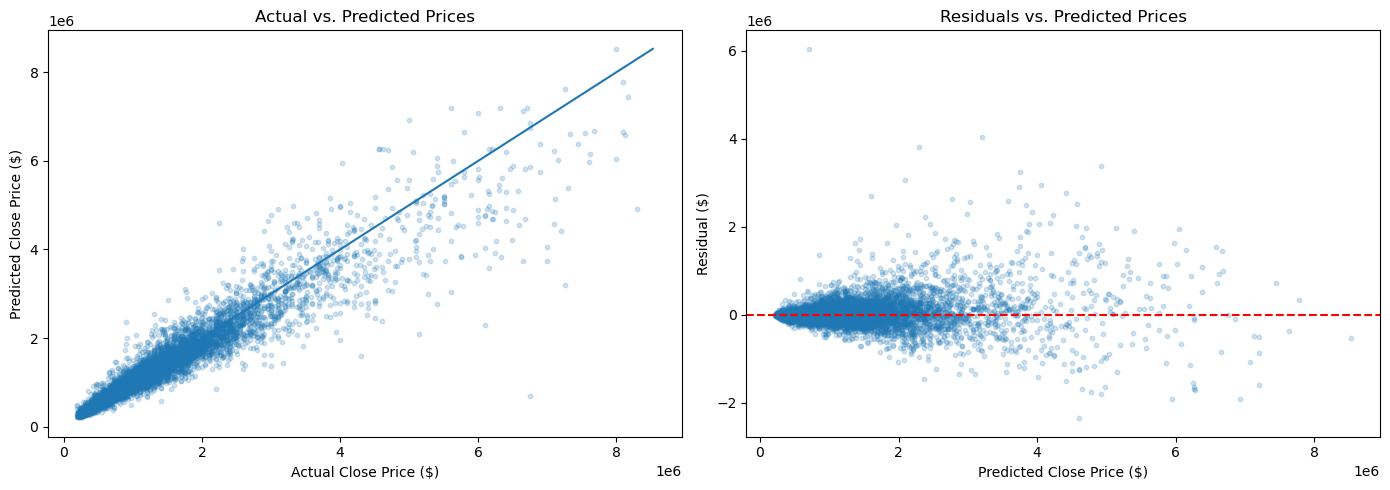

In [58]:
# Plot actual vs. predicted prices and residuals
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs. predicted prices
axes[0].scatter(y_actual_val, y_pred_val, alpha=0.2, s=10)
price_min = min(y_actual_val.min(), y_pred_val.min())
price_max = max(y_actual_val.max(), y_pred_val.max())

axes[0].plot([price_min, price_max], [price_min, price_max])
axes[0].set_xlabel("Actual Close Price ($)")
axes[0].set_ylabel("Predicted Close Price ($)")
axes[0].set_title("Actual vs. Predicted Prices")

# Residuals vs. predicted prices
axes[1].scatter(y_pred_val, residuals_val, alpha=0.2, s=10)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted Close Price ($)")
axes[1].set_ylabel("Residual ($)")
axes[1].set_title("Residuals vs. Predicted Prices")

plt.tight_layout()
plt.show()

### Validation Performance by Property Price Range

Validation predictions from the Tuned XGBoost model combining school district, HOA, and flooring features were grouped into five price ranges based on actual sale prices. R², MAPE, and MdAPE were calculated for each group to examine how prediction accuracy varies across different property values.

In [59]:
# Create a DataFrame with actual and predicted validation prices
price_analysis_val_df = pd.DataFrame({"ActualPrice": np.asarray(y_actual_val), "PredictedPrice": np.asarray(y_pred_val)})

# Define property price ranges
price_bins = [0, 500000, 1000000, 2000000, 4000000, np.inf]
price_labels = ["Under $500K", "$500K–$1M", "$1M–$2M", "$2M–$4M", "$4M+"]

# Assign properties to price ranges based on actual sale prices
price_analysis_val_df["PriceRange"] = pd.cut(price_analysis_val_df["ActualPrice"], bins=price_bins,
                                             labels=price_labels,right=False)

# Calculate validation metrics for each price range
price_range_results_val = []

for price_range, group in price_analysis_val_df.groupby("PriceRange", observed=True):

    actual = group["ActualPrice"]
    predicted = group["PredictedPrice"]

    price_range_results_val.append({"Price Range": price_range, "Count": len(group),\
        "R²": r2_score(actual, predicted) if len(group) >= 2 else np.nan, "MAPE (%)": mape(actual, predicted),
        "MdAPE (%)": mdape(actual, predicted)})

# Create validation results DataFrame
price_range_results_val_df = pd.DataFrame(price_range_results_val)
display(price_range_results_val_df)

,Price Range,Count,R²,MAPE (%),MdAPE (%)
0,Under $500K,1635,0.179142,12.091962,7.136653
1,$500K–$1M,4908,0.501681,8.388799,5.781584
2,$1M–$2M,3361,0.352289,11.124357,8.863679
3,$2M–$4M,1221,0.166852,13.451175,10.902928
4,$4M+,265,-0.477520,18.836238,16.965428


**Key Findings:**

* Best Performance: Properties priced between $500K and $1M achieved the lowest prediction errors, with MAPE of 8.39% and MdAPE of 5.78%.

* Higher-Priced Properties: Prediction errors increased for expensive homes, reaching a MAPE of 18.84% and MdAPE of 16.97% for properties above $4M.

* R²: Performance varied across price ranges, with the highest R² of 0.5017 for properties between $500K and $1M. The negative R² of −0.4775 for properties above $4M indicates weaker predictive performance within this price range. R² should be interpreted cautiously because each price band has a restricted range of actual prices.

Overall, the tuned XGBoost model performed best for mid-priced properties, while higher-priced properties remained more challenging to predict.

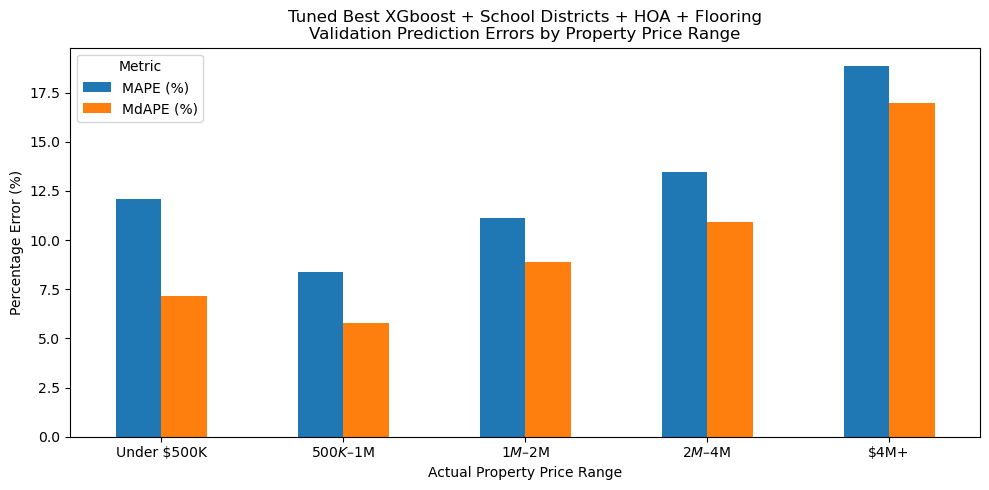

In [60]:
# Plot validation MAPE and MdAPE by property price range
ax = price_range_results_val_df.plot(x="Price Range", y=["MAPE (%)", "MdAPE (%)"], kind="bar", figsize=(10, 5), rot=0)
ax.set_title("Tuned Best XGboost + School Districts + HOA + Flooring\nValidation Prediction Errors by Property Price Range")
ax.set_xlabel("Actual Property Price Range")
ax.set_ylabel("Percentage Error (%)")
ax.legend(title="Metric")
plt.tight_layout()
plt.show()

### Save Validation Results — March 2026

The validation results from the XGBoost and LightGBM models, including the tuned XGBoost configuration are consolidated into a single comparison table containing R², MAE, MAPE, and MdAPE.The results are saved as advanced_validation_results_march_2026.csv in the project's results folder for comparison with baseline and feature-engineered models in 06_evaluation.ipynb.

The April 2026 test set remains reserved for the final evaluation of the selected models.

In [61]:
# Save March 2026 validation results
validation_results_advanced_df.to_csv("../results/advanced_validation_results_march_2026.csv", index=False)

display(validation_results_advanced_df.round(4))

,Model,Training R²,Validation R²,Validation MAE ($),Validation MAPE (%),Validation MdAPE (%)
0,XGBoost,0.9100,0.8934,156589.1681,11.6534,8.2339
1,LightGBM,0.8795,0.8727,170188.5208,12.5807,9.0501
2,XGBoost + Ratio,0.9117,0.8933,157253.7670,11.7818,8.3757
3,LightGBM + Ratio,0.8797,0.8733,169904.9812,12.5591,8.9572
4,XGBoost + School Districts,0.9116,0.8932,156261.9767,11.6801,8.3810
5,LightGBM + School Districts,0.8815,0.8732,168998.9772,12.5019,8.9255
6,XGBoost + HOA,0.9120,0.8940,155218.7345,11.5801,8.1917
7,LightGBM + HOA,0.8815,0.8748,168508.8157,12.4377,8.8635
8,XGBoost + Comparable Sales,0.9131,0.8967,153881.0114,11.6015,8.2839
9,LightGBM + Comparable Sales,0.8857,0.8877,161894.1207,12.1498,8.7626


### Next Steps

**Week 8 (Final Evaluation):** Combine the saved validation results from Notebooks 04 and 05 to compare model performance using R², MAE, MAPE, and MdAPE. Compare Random Forest and tuned XGBoost prediction errors across different property price ranges and identify the final model(s) for testing. The final evaluation results will be consolidated in 06_evaluation.ipynb and saved as metrics_summary.csv.

**Test Set:** The April 2026 test set will remain untouched until model selection is finalized. The selected models will then be evaluated on the test set to assess their generalization performance.